In [ ]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as pl
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim

from models.mlp_classifier import build_mlp_classifier, extract_features


In [4]:
cwd = Path.cwd().resolve()

PROJECT_ROOT = None

for path in [cwd, *cwd.parents]:
    if (path / "models" / "mlp_classifier.py").is_file() and (
        path / "data_loader.py"
    ).is_file():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate project root. "
        "Expected models/mlp_classifier.py and data_loader.py."
    )


In [7]:
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Working directory : {cwd}")
print(f"Project root      : {PROJECT_ROOT}")


Working directory : D:\Main\sem5\deep-learning\ASG_2\notebooks
Project root      : D:\Main\sem5\deep-learning\ASG_2


In [8]:
DATA_DIR = PROJECT_ROOT / "data"

RESULTS_DIR = PROJECT_ROOT / "results"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
METRICS_DIR = RESULTS_DIR / "metrics"
FEATURES_DIR = RESULTS_DIR / "features"
FIGURES_DIR = RESULTS_DIR / "figures"


In [10]:
for directory in [CHECKPOINT_DIR, METRICS_DIR, FEATURES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


In [12]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "xpu")

model = build_mlp_classifier().to(DEVICE)

checkpoint_path = CHECKPOINT_DIR / "mlp_classifier_best.pth"


In [13]:
legacy_checkpoint = (
    PROJECT_ROOT / "notebooks" / "results" / "checkpoints" / "mlp_classifier_best.pth"
)

if not checkpoint_path.is_file():
    if legacy_checkpoint.is_file():
        raise FileNotFoundError(
            f"Checkpoint still exists in old location:\n"
            f"{legacy_checkpoint}\n\n"
            f"Move it to:\n{checkpoint_path}"
        )

    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)

model.load_state_dict(checkpoint)
model.eval()

print("\nMLP Classifier loaded successfully!")
print(f"Device     : {DEVICE}")
print(f"Checkpoint : {checkpoint_path}")



MLP Classifier loaded successfully!
Device     : xpu
Checkpoint : D:\Main\sem5\deep-learning\ASG_2\results\checkpoints\mlp_classifier_best.pth


In [15]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

print("Number of classes:", len(CLASS_NAMES))


Number of classes: 10


In [16]:
# Extract trained weights
W1 = model[1].weight
W2 = model[3].weight
W3 = model[5].weight

print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)


W1: torch.Size([256, 784])
W2: torch.Size([64, 256])
W3: torch.Size([10, 64])


In [17]:
# Generate onehot vectors
class_ids = torch.arange(10, device=DEVICE)

y = F.one_hot(class_ids, num_classes=10).float()

# Top-down weight transposition
with torch.inference_mode():
    # Class space -> latent space
    z_hat = F.relu(y @ W3)

    # Latent space -> hidden representation
    h1_hat = F.relu(z_hat @ W2)

    # Hidden representation -> pixel space
    x_hat = torch.sigmoid(h1_hat @ W1)

    # Reshape into image dimensions
    generated_images = x_hat.reshape(-1, 1, 28, 28)

print("Generated images:", generated_images.shape)
print("Pixel range:", generated_images.min().item(), "-", generated_images.max().item())


Generated images: torch.Size([10, 1, 28, 28])
Pixel range: 0.007055715657770634 - 0.9688597917556763


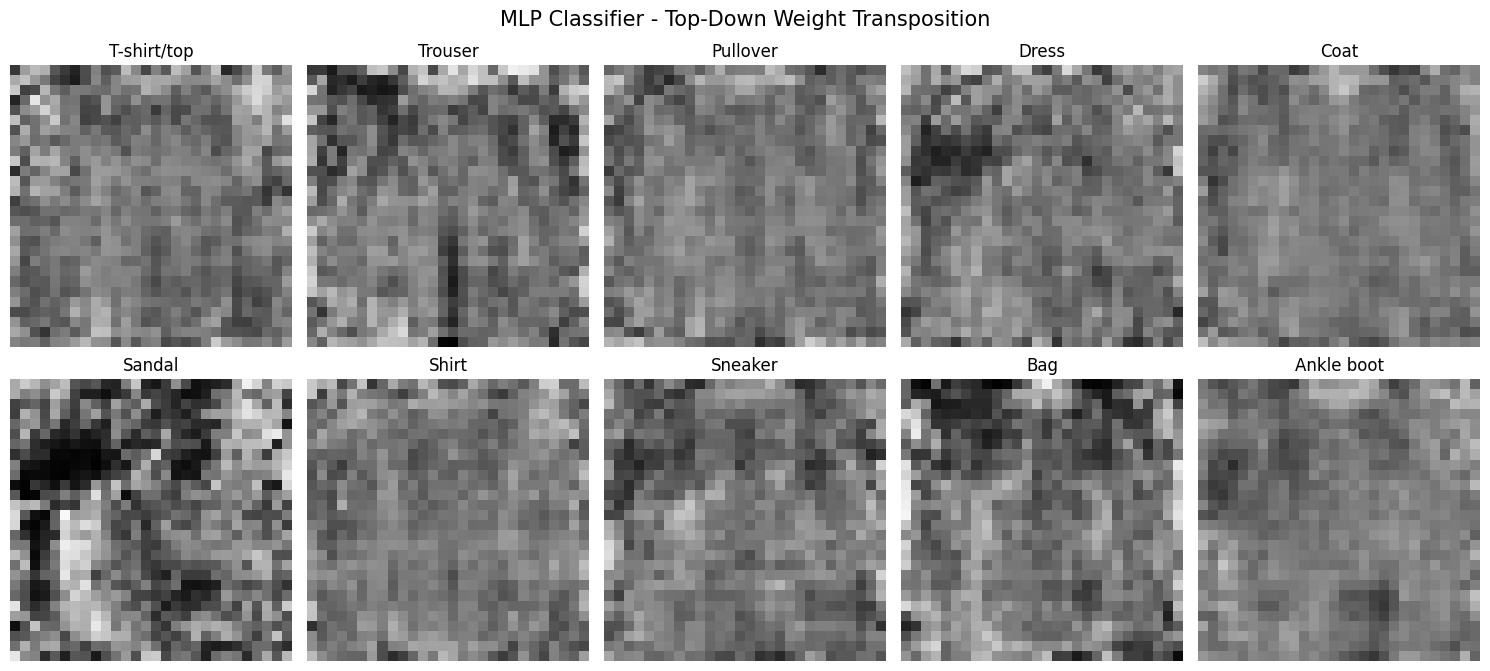

Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\exp1_weight_transposition.png


In [18]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].squeeze().cpu().numpy()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    ax.set_title(CLASS_NAMES[i])
    ax.axis("off")

fig.suptitle("MLP Classifier - Top-Down Weight Transposition", fontsize=15)

plt.tight_layout()

# Save figure before displaying
figure_path = FIGURES_DIR / "exp1_weight_transposition.png"

fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved:", figure_path)


In [19]:
# Save generated images
output_path = FEATURES_DIR / "mlp_weight_transposition.pt"

torch.save(generated_images.cpu(), output_path)

print("Generated images saved:", output_path)


Generated images saved: D:\Main\sem5\deep-learning\ASG_2\results\features\mlp_weight_transposition.pt


In [21]:
weight_matrices = {"W1": W1, "W2": W2, "W3": W3}

print("WEIGHT MATRIX ANALYSIS")

for name, weight in weight_matrices.items():
    weight = weight.detach()

    gram_matrix = weight.T @ weight

    identity = torch.eye(weight.shape[1], device=weight.device, dtype=weight.dtype)

    error = torch.linalg.norm(gram_matrix - identity, ord="fro")

    relative_error = error / torch.linalg.norm(identity, ord="fro")

    rank = torch.linalg.matrix_rank(weight)

    print(f"\n{name}")
    print("Weight shape:", tuple(weight.shape))
    print("Matrix rank:", rank.item())
    print("Relative Frobenius error:", relative_error.item())
    print("Is square:", weight.shape[0] == weight.shape[1])


WEIGHT MATRIX ANALYSIS

W1
Weight shape: (256, 784)
Matrix rank: 256
Relative Frobenius error: 17.169668197631836
Is square: False

W2
Weight shape: (64, 256)
Matrix rank: 64
Relative Frobenius error: 4.283871650695801
Is square: False

W3
Weight shape: (10, 64)
Matrix rank: 10
Relative Frobenius error: 1.7942103147506714
Is square: False


In [22]:
from data_loader import get_dataloaders

_, _, test_loader = get_dataloaders(root=DATA_DIR, batch_size=128, seed=42)

print("Test samples:", len(test_loader.dataset))


Test samples: 7000


In [25]:
original_images = []
latent_features = []
projected_images = []
all_labels = []

model.eval()

W1 = model[1].weight
W2 = model[3].weight

with torch.inference_mode():
    for images, labels in test_loader:
        images_device = images.to(DEVICE)

        # Extract latent features from classifier
        z = extract_features(model, images_device)

        # Transpose projection
        h1_hat = F.relu(z @ W2)
        x_hat = torch.sigmoid(h1_hat @ W1)

        # Store results
        original_images.append(images.flatten(start_dim=1))

        latent_features.append(z.cpu())
        projected_images.append(x_hat.cpu())
        all_labels.append(labels)

original_images = torch.cat(original_images)
latent_features = torch.cat(latent_features)
projected_images = torch.cat(projected_images)
all_labels = torch.cat(all_labels)

print("Original:", original_images.shape)
print("Latent:", latent_features.shape)
print("Projected:", projected_images.shape)


Original: torch.Size([7000, 784])
Latent: torch.Size([7000, 64])
Projected: torch.Size([7000, 784])


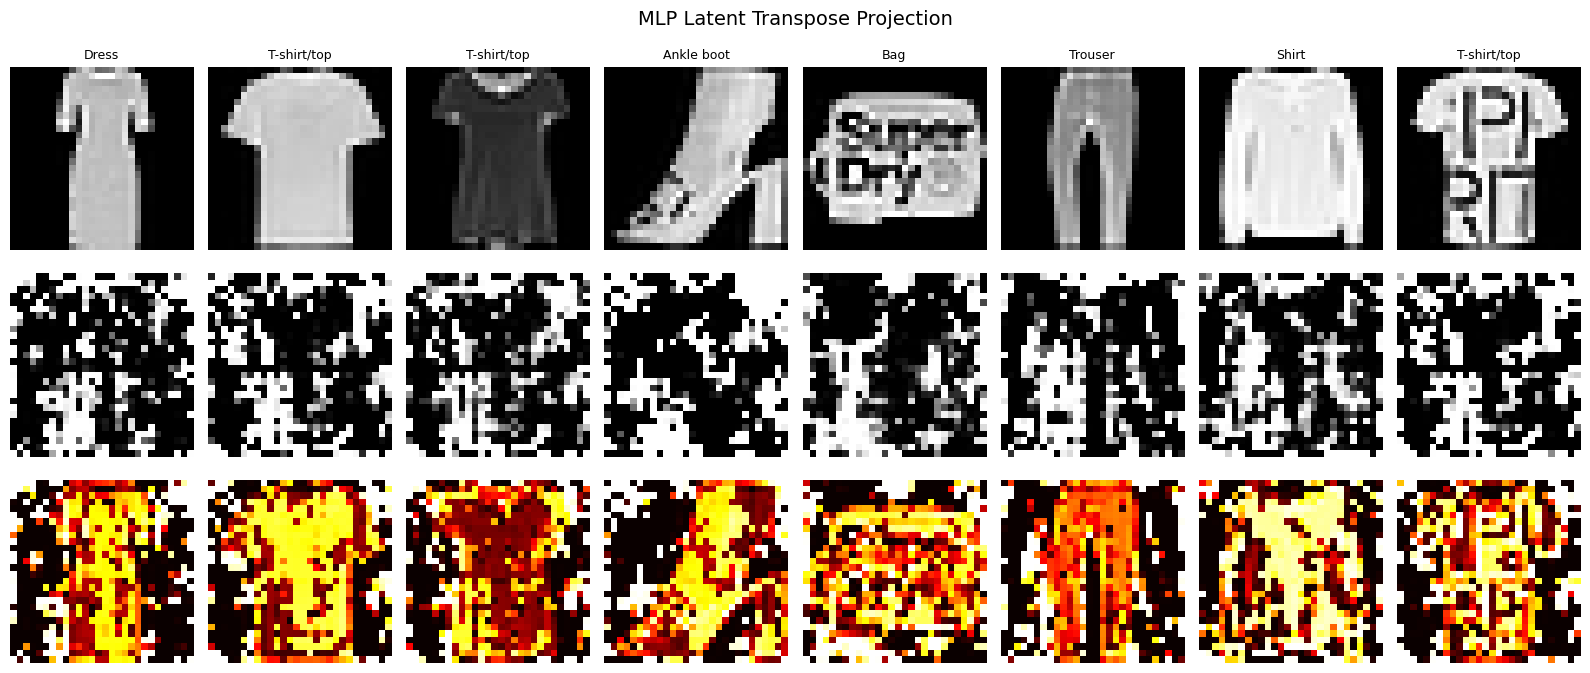

In [27]:
num_samples = 8

fig, axes = plt.subplots(3, num_samples, figsize=(16, 7))

for i in range(num_samples):
    original = original_images[i].reshape(28, 28)
    projected = projected_images[i].reshape(28, 28)

    label = all_labels[i].item()

    # Original images
    axes[0, i].imshow(original.numpy(), cmap="gray", vmin=0, vmax=1)

    axes[0, i].set_title(CLASS_NAMES[label], fontsize=9)

    axes[1, i].imshow(projected.numpy(), cmap="gray", vmin=0, vmax=1)

    difference = torch.abs(original - projected)

    axes[2, i].imshow(difference.numpy(), cmap="hot")

    axes[0, i].axis("off")
    axes[1, i].axis("off")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Projection", fontsize=10)
axes[2, 0].set_ylabel("Difference", fontsize=10)

fig.suptitle("MLP Latent Transpose Projection", fontsize=14)
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "exp2_latent_transpose_projection.png", dpi=300, bbox_inches="tight"
)

plt.show()


In [29]:
mse_per_sample = torch.mean((original_images - projected_images) ** 2, dim=1)

mean_mse = mse_per_sample.mean().item()

print("LATENT TRANSPOSE PROJECTION")
print(f"Test samples: {len(original_images)}")
print(f"Mean MSE: {mean_mse:.6f}")
print(f"Min MSE:  {mse_per_sample.min().item():.6f}")
print(f"Max MSE:  {mse_per_sample.max().item():.6f}")


LATENT TRANSPOSE PROJECTION
Test samples: 7000
Mean MSE: 0.288756
Min MSE:  0.185442
Max MSE:  0.497177


In [30]:
experiment_2_results = {
    "original_images": original_images,
    "latent_features": latent_features,
    "projected_images": projected_images,
    "labels": all_labels,
    "mse_per_sample": mse_per_sample,
    "mean_mse": mean_mse,
}

torch.save(experiment_2_results, FEATURES_DIR / "mlp_latent_transpose_projection.pt")

print("Experiment 2 artifacts saved.")


Experiment 2 artifacts saved.


In [35]:
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001


In [ ]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE, seed=42)

train_eval_loader = DataLoader(
    train_loader.dataset, batch_size=BATCH_SIZE, shuffle=False
)

val_eval_loader = DataLoader(val_loader.dataset, batch_size=BATCH_SIZE, shuffle=False)

test_eval_loader = DataLoader(test_loader.dataset, batch_size=BATCH_SIZE, shuffle=False)


def extract_mlp_pairs(loader):
    model.eval()

    all_features = []
    all_images = []

    with torch.inference_mode():
        for images, _ in loader:
            images_device = images.to(DEVICE)

            # Extract 64-dimensional frozen MLP features
            z = model[:5](images_device)

            all_features.append(z.cpu())
            all_images.append(images.flatten(start_dim=1).cpu())

    return (torch.cat(all_features), torch.cat(all_images))


100%|██████████| 26.4M/26.4M [00:04<00:00, 6.59MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 140kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 788kB/s]


In [38]:
z_train, x_train = extract_mlp_pairs(train_eval_loader)
z_val, x_val = extract_mlp_pairs(val_eval_loader)
z_test, x_test = extract_mlp_pairs(test_eval_loader)

print("Training latent:", z_train.shape)
print("Training images:", x_train.shape)

print("Validation latent:", z_val.shape)
print("Test latent:", z_test.shape)


Training latent: torch.Size([56000, 64])
Training images: torch.Size([56000, 784])
Validation latent: torch.Size([7000, 64])
Test latent: torch.Size([7000, 64])


In [39]:
train_frozen_dataset = TensorDataset(z_train, x_train)
val_frozen_dataset = TensorDataset(z_val, x_val)
test_frozen_dataset = TensorDataset(z_test, x_test)

train_frozen_loader = DataLoader(
    train_frozen_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_frozen_loader = DataLoader(val_frozen_dataset, batch_size=BATCH_SIZE, shuffle=False)

test_frozen_loader = DataLoader(
    test_frozen_dataset, batch_size=BATCH_SIZE, shuffle=False
)


In [40]:
def build_decoder(latent_dim=64):
    return nn.Sequential(
        nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()
    )


frozen_decoder = build_decoder().to(DEVICE)

criterion = nn.MSELoss()

optimizer_frozen = optim.Adam(frozen_decoder.parameters(), lr=LEARNING_RATE)

print(frozen_decoder)


Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=784, bias=True)
  (3): Sigmoid()
)


In [41]:
def train_decoder_epoch(decoder, loader, optimizer):
    decoder.train()

    total_loss = 0.0
    total_samples = 0

    for z, images in loader:
        z = z.to(DEVICE)
        images = images.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        reconstruction = decoder(z)
        loss = criterion(reconstruction, images)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    return total_loss / total_samples


def evaluate_decoder(decoder, loader):
    decoder.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for z, images in loader:
            z = z.to(DEVICE)
            images = images.to(DEVICE)

            reconstruction = decoder(z)
            loss = criterion(reconstruction, images)

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    return total_loss / total_samples


In [42]:
frozen_history = []

best_frozen_val_loss = float("inf")

frozen_checkpoint_path = CHECKPOINT_DIR / "mlp_frozen_decoder_best.pth"

print("Training Frozen Latent Decoder...\n")

for epoch in range(EPOCHS):
    start_time = time.perf_counter()

    train_loss = train_decoder_epoch(
        frozen_decoder, train_frozen_loader, optimizer_frozen
    )

    val_loss = evaluate_decoder(frozen_decoder, val_frozen_loader)

    epoch_time = time.perf_counter() - start_time

    frozen_history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "epoch_time": epoch_time,
        }
    )

    if val_loss < best_frozen_val_loss:
        best_frozen_val_loss = val_loss

        torch.save(frozen_decoder.state_dict(), frozen_checkpoint_path)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Train MSE: {train_loss:.6f} "
        f"| Val MSE: {val_loss:.6f} "
        f"| Time: {epoch_time:.2f}s"
    )

# Restore best decoder
frozen_decoder.load_state_dict(torch.load(frozen_checkpoint_path, map_location=DEVICE))

print("\nFrozen Decoder training completed.")


Training Frozen Latent Decoder...

Epoch [01/30] | Train MSE: 0.036585 | Val MSE: 0.027530 | Time: 6.19s
Epoch [02/30] | Train MSE: 0.025375 | Val MSE: 0.023982 | Time: 4.08s
Epoch [03/30] | Train MSE: 0.023063 | Val MSE: 0.022546 | Time: 5.89s
Epoch [04/30] | Train MSE: 0.021826 | Val MSE: 0.021511 | Time: 5.98s
Epoch [05/30] | Train MSE: 0.020998 | Val MSE: 0.020900 | Time: 6.16s
Epoch [06/30] | Train MSE: 0.020391 | Val MSE: 0.020457 | Time: 6.07s
Epoch [07/30] | Train MSE: 0.019927 | Val MSE: 0.019928 | Time: 6.04s
Epoch [08/30] | Train MSE: 0.019567 | Val MSE: 0.019687 | Time: 6.09s
Epoch [09/30] | Train MSE: 0.019297 | Val MSE: 0.019781 | Time: 6.05s
Epoch [10/30] | Train MSE: 0.019060 | Val MSE: 0.019259 | Time: 6.22s
Epoch [11/30] | Train MSE: 0.018783 | Val MSE: 0.019184 | Time: 5.95s
Epoch [12/30] | Train MSE: 0.018611 | Val MSE: 0.018964 | Time: 4.00s
Epoch [13/30] | Train MSE: 0.018427 | Val MSE: 0.018773 | Time: 3.74s
Epoch [14/30] | Train MSE: 0.018288 | Val MSE: 0.018665